In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")    
plt.rcParams['figure.figsize'] = (12, 6)



In [87]:
df = pd.read_csv("earthquake_data_tsunami.csv")

In [88]:
type(df)

pandas.DataFrame

In [89]:
df.shape

(782, 13)

In [90]:
df.head()

,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
0,7.0,8,7,768,117,0.509,17.0,14.000,-9.7963,159.596,2022,11,1
1,6.9,4,4,735,99,2.229,34.0,25.000,-4.9559,100.738,2022,11,0
2,7.0,3,3,755,147,3.125,18.0,579.000,-20.0508,-178.346,2022,11,1
3,7.3,5,5,833,149,1.865,21.0,37.000,-19.2918,-172.129,2022,11,1
4,6.6,0,2,670,131,4.998,27.0,624.464,-25.5948,178.278,2022,11,1


In [91]:
df.tail()

,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
777,7.7,0,8,912,427,0.0,0.0,60.0,13.0490,-88.660,2001,1,0
778,6.9,5,7,745,0,0.0,0.0,36.4,56.7744,-153.281,2001,1,0
779,7.1,0,7,776,372,0.0,0.0,103.0,-14.9280,167.170,2001,1,0
780,6.8,0,5,711,64,0.0,0.0,33.0,6.6310,126.899,2001,1,0
781,7.5,0,7,865,324,0.0,0.0,33.0,6.8980,126.579,2001,1,0


In [92]:
df.info()

print()
print(f"Jumlah Columns Dan Baris : {df.shape}")
print(f"nilai Nan :\n{df.isna().sum()}")
print(f"nilai Duplicated : {df.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   magnitude  782 non-null    float64
 1   cdi        782 non-null    int64  
 2   mmi        782 non-null    int64  
 3   sig        782 non-null    int64  
 4   nst        782 non-null    int64  
 5   dmin       782 non-null    float64
 6   gap        782 non-null    float64
 7   depth      782 non-null    float64
 8   latitude   782 non-null    float64
 9   longitude  782 non-null    float64
 10  Year       782 non-null    int64  
 11  Month      782 non-null    int64  
 12  tsunami    782 non-null    int64  
dtypes: float64(6), int64(7)
memory usage: 79.6 KB

Jumlah Columns Dan Baris : (782, 13)
nilai Nan :
magnitude    0
cdi          0
mmi          0
sig          0
nst          0
dmin         0
gap          0
depth        0
latitude     0
longitude    0
Year         0
Month        0
tsunami      0
dtype: int

In [93]:
df.duplicated().sum()

np.int64(0)

In [94]:
df.describe()

,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
count,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000
mean,6.941125,4.333760,5.964194,870.108696,230.250639,1.325757,25.038990,75.883199,3.538100,52.609199,2012.280051,6.563939,0.388747
std,0.445514,3.169939,1.462724,322.465367,250.188177,2.218805,24.225067,137.277078,27.303429,117.898886,6.099439,3.507866,0.487778
min,6.500000,0.000000,1.000000,650.000000,0.000000,0.000000,0.000000,2.700000,-61.848400,-179.968000,2001.000000,1.000000,0.000000
25%,6.600000,0.000000,5.000000,691.000000,0.000000,0.000000,14.625000,14.000000,-14.595600,-71.668050,2007.000000,3.250000,0.000000
50%,6.800000,5.000000,6.000000,754.000000,140.000000,0.000000,20.000000,26.295000,-2.572500,109.426000,2013.000000,7.000000,0.000000
75%,7.100000,7.000000,7.000000,909.750000,445.000000,1.863000,30.000000,49.750000,24.654500,148.941000,2017.000000,10.000000,1.000000
max,9.100000,9.000000,9.000000,2910.000000,934.000000,17.654000,239.000000,670.810000,71.631200,179.662000,2022.000000,12.000000,1.000000


In [95]:
df.nunique()

magnitude     24
cdi           10
mmi            9
sig          339
nst          312
dmin         369
gap          256
depth        303
latitude     778
longitude    777
Year          22
Month         12
tsunami        2
dtype: int64

In [96]:
data = df.columns

In [97]:
for col in data:
    print(f"kolom {col} :")
    print('nilai unik : ')
    print(df[col].unique())

kolom magnitude :
nilai unik : 
[7.   6.9  7.3  6.6  6.8  6.7  7.6  6.5  7.2  7.5  7.1  8.1  8.2  7.4
 7.7  7.8  8.   7.9  8.3  8.6  9.1  8.8  8.4  8.16]
kolom cdi :
nilai unik : 
[8 4 3 5 0 1 7 9 2 6]
kolom mmi :
nilai unik : 
[7 4 3 5 2 6 8 9 1]
kolom sig :
nilai unik : 
[ 768  735  755  833  670  711  797 1179 1799  887  756  761  965 1043
  672 1351  653  876  733  762  763  738  806 2397  708  712  690  651
  785  650  674  691  730  976 1012  921  854 1094  688  995  740  826
  684 2504  776  741  734 2331 1009  868  846 1237 1252  935  830  652
 1025  698  694  919 1052 1021  843  932 1612  918  739  802 1527 1165
  732  824  749  716  784 1111  820 1494  873  835 1320  671  678 1410
  879  770 1812 1247  825  799  673  780  844  656  875  947  809  791
  747 1646  952  886 1890  929  717  869 1145  909 1600  715  803  822
  871 1790  693  954  655  669  758 2026  979 1075 1570 1206 1050  743
 1704 1392  696  719  697  943 1384 1870 1623  998  771  676 1153 2790
  661  727 1686 

<Axes: >

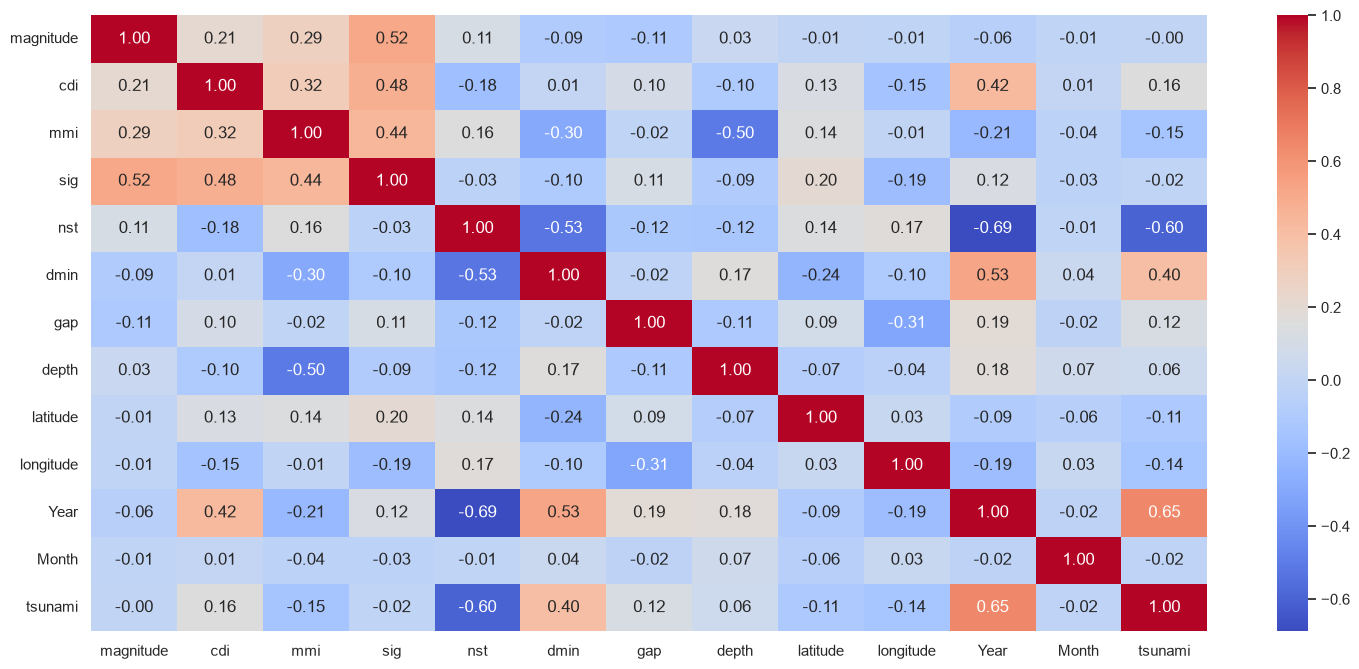

In [98]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(18,8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

In [99]:
df.quantile()

magnitude       6.8000
cdi             5.0000
mmi             6.0000
sig           754.0000
nst           140.0000
dmin            0.0000
gap            20.0000
depth          26.2950
latitude       -2.5725
longitude     109.4260
Year         2013.0000
Month           7.0000
tsunami         0.0000
Name: 0.5, dtype: float64

In [100]:
for col in data:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_bound , lower_bound,
              np.where(df[col] > upper_bound, upper_bound, df[col]))

    print(f"""COLOMNS : {col}
            Q1 : {Q1}
            Q3 : {Q3}
            IQR : {IQR}
        LOWER BOUND : {lower_bound}
        UPPER BOUND : {upper_bound}
""")



COLOMNS : magnitude
            Q1 : 6.6
            Q3 : 7.1
            IQR : 0.5
        LOWER BOUND : 5.85
        UPPER BOUND : 7.85

COLOMNS : cdi
            Q1 : 0.0
            Q3 : 7.0
            IQR : 7.0
        LOWER BOUND : -10.5
        UPPER BOUND : 17.5

COLOMNS : mmi
            Q1 : 5.0
            Q3 : 7.0
            IQR : 2.0
        LOWER BOUND : 2.0
        UPPER BOUND : 10.0

COLOMNS : sig
            Q1 : 691.0
            Q3 : 909.75
            IQR : 218.75
        LOWER BOUND : 362.875
        UPPER BOUND : 1237.875

COLOMNS : nst
            Q1 : 0.0
            Q3 : 445.0
            IQR : 445.0
        LOWER BOUND : -667.5
        UPPER BOUND : 1112.5

COLOMNS : dmin
            Q1 : 0.0
            Q3 : 1.863
            IQR : 1.863
        LOWER BOUND : -2.7945
        UPPER BOUND : 4.657500000000001

COLOMNS : gap
            Q1 : 14.625
            Q3 : 30.0
            IQR : 15.375
        LOWER BOUND : -8.4375
        UPPER BOUND : 53.0625

COLOMN

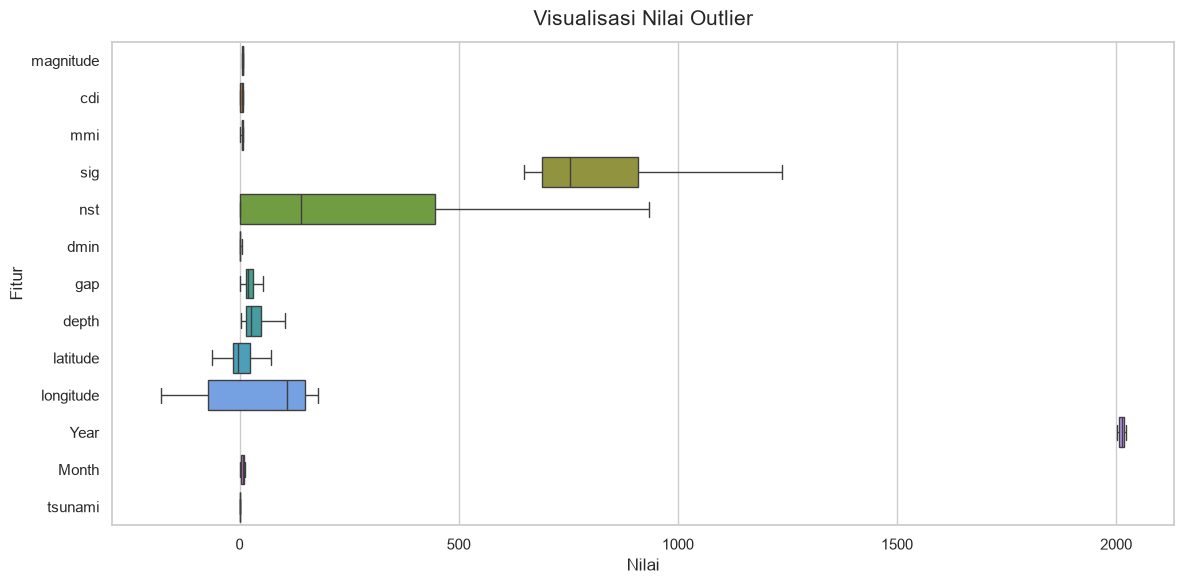

BERIKUT DATA OUTLIER SETELAH DI BUAT LEBIH RAPIH


In [101]:
columns = data
plt.Figure(figsize=(18,8))
sns.boxplot(data=df[columns],orient='h')
plt.title("Visualisasi Nilai Outlier", fontsize=15, pad=12)
plt.xlabel("Nilai" , fontsize=12)
plt.ylabel("Fitur", fontsize=12)

plt.tight_layout()
plt.show()

print("berikut data outlier setelah di buat lebih rapih".upper())

In [102]:
num_cols = df.drop(columns=['tsunami']).columns.tolist()

In [103]:
x = df.drop(columns=['tsunami'])
y = df['tsunami']

In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    train_size=0.8,
    random_state=42,
    stratify=y
)

print(f"""
Data Training : {X_train.shape}
Data Testing : {X_test.shape}""")


Data Training : (625, 12)
Data Testing : (157, 12)


In [105]:
models = {
    "LogisticRegression" : LogisticRegression(),
    " Random Forest " : RandomForestClassifier(random_state=42),
    " Decision Tree" : DecisionTreeClassifier(), 
}

In [106]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num' , StandardScaler(), num_cols),
    ],
remainder='passthrough'
)

In [107]:
print(type(num_cols))
num_cols

<class 'list'>


['magnitude',
 'cdi',
 'mmi',
 'sig',
 'nst',
 'dmin',
 'gap',
 'depth',
 'latitude',
 'longitude',
 'Year',
 'Month']

In [108]:
result_list = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor',preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:,1] if hasattr(pipeline, "predict_proba") else None

    acc = accuracy_score(y_test,y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.False_

    result_list.append({
            'Model': name,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'ROC-AUC': roc_auc
        })
    
df_results = pd.DataFrame(result_list).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print(df_results)   

    

                Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0      Random Forest   0.929936   0.878788  0.950820  0.913386  0.962944
1       Decision Tree  0.904459   0.883333  0.868852  0.876033  0.897968
2  LogisticRegression  0.859873   0.774648  0.901639  0.833333  0.921448


In [113]:
distribusi = pd.DataFrame({
    "Jumlah" : df['tsunami'].value_counts(),
    "Persentasi" : df['tsunami'].value_counts(normalize=True) * 100
})

distribusi

,Jumlah,Persentasi
tsunami,,
0.0,478,61.12532
1.0,304,38.87468


In [117]:
best_base_pipeline = Pipeline(steps=[
    'preprocessor' , preprocessor,
    'model' , LogisticRegression()
])

In [118]:
param_grid = {
    'classifer' : [0.001, 0.01, 0.1, 1, 10],
    'classifer_penalty' : ['l1', 'l2'],
    'classifer_solver' : ['liblinear', 'saga'],
    'classifer_max.iter' : [100, 300, 500],
}